In [1]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rasterio.enums import Resampling

ROOT = Path.cwd().resolve()

if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
VIRTIS_DIR = DATA_DIR / "VIRTIS"
RASTER_DIR = VIRTIS_DIR / "raster"

folders = [
    "VIRTIS_emissivity",
    "VIRTIS_coverage",
    "VIRTIS_surface_radiance"
]

for folder in folders:

    path = RASTER_DIR / folder

    print(f"\n{'=' * 60}")
    print(folder)
    print("=" * 60)

    if not path.exists():
        print("Folder not found:", path)
        continue

    for file in sorted(path.rglob("*")):
        if file.is_file():
            print(
                file.relative_to(RASTER_DIR),
                f"({file.stat().st_size / 1e6:.2f} MB)"
            )


VIRTIS_emissivity
VIRTIS_emissivity/VIRTIS_emissivity_-40S-90N.tif (0.02 MB)
VIRTIS_emissivity/VIRTIS_emissivity_-40S-90N.tif.aux.xml (0.01 MB)

VIRTIS_coverage
VIRTIS_coverage/VIRTIS_coverage_-40S-90N.tif (0.01 MB)
VIRTIS_coverage/VIRTIS_coverage_-40S-90N.tif.aux.xml (0.00 MB)

VIRTIS_surface_radiance
VIRTIS_surface_radiance/VIRTIS_surface_radiance_-40S-90N.tif (0.02 MB)
VIRTIS_surface_radiance/VIRTIS_surface_radiance_-40S-90N.tif.aux.xml (0.01 MB)


In [2]:
# Find possible emissivity rasters

EMISSIVITY_DIR = RASTER_DIR / "VIRTIS_emissivity"

raster_extensions = {
    ".tif", ".tiff", ".img", ".vrt", ".jp2"
}

emissivity_files = sorted([
    p for p in EMISSIVITY_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in raster_extensions
])

for file in emissivity_files:

    print("\n" + "=" * 70)
    print("File:", file.name)

    with rasterio.open(file) as src:

        print("Shape:", src.height, src.width)
        print("Bands:", src.count)
        print("Data type:", src.dtypes)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Scales:", src.scales)
        print("Offsets:", src.offsets)
        print("Band descriptions:", src.descriptions)
        print("Metadata tags:", src.tags())

        # Sample only a reduced array for numerical inspection
        sample = src.read(
            1,
            out_shape=(
                min(300, src.height),
                min(300, src.width)
            ),
            masked=True,
            resampling=Resampling.nearest
        )

        values = sample.compressed()
        values = values[np.isfinite(values)]

        if len(values) > 0:
            print("\nStored value statistics:")
            print("Min:", values.min())
            print("Median:", np.median(values))
            print("Max:", values.max())
        else:
            print("No valid sampled pixels")


File: VIRTIS_emissivity_-40S-90N.tif
Shape: 41 41
Bands: 3
Data type: ('float32', 'float32', 'float32')
CRS: PROJCS["Equirectangular Venus",GEOGCS["GCS_Venus",DATUM["D_Venus",SPHEROID["Venus",6051000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (26384.11355641184, 26384.11355641184)
Bounds: BoundingBox(left=-10052347.264992911, bottom=-4749140.4401541315, right=-8970598.609180026, top=-3667391.784341246)
NoData: None
Scales: (1.0, 1.0, 1.0)
Offsets: (0.0, 0.0, 0.0)
Band descriptions: (None, None, None)
Metadata tags: {'AREA_OR_POINT': 'Area'}

Stored value statistics:
Min: 0.97028506
Median: 0.9970431
Max: 1.0427842


In [3]:
virtis_file = emissivity_files[0]

with rasterio.open(virtis_file) as src:

    bands = src.read(masked=True).astype(float)

    for i in range(src.count):
        print(f"\nBand {i+1}")
        print("Tags:", src.tags(i+1))
        print("Mask flags:", src.mask_flag_enums[i])

        values = bands[i].compressed()
        values = values[np.isfinite(values)]

        print("Valid pixels:", len(values))

        if len(values):
            print("Min:", values.min())
            print("Median:", np.median(values))
            print("Max:", values.max())

    print("\nBand comparisons:")
    for i in range(src.count):
        for j in range(i+1, src.count):

            a = np.ma.filled(bands[i], np.nan)
            b = np.ma.filled(bands[j], np.nan)

            valid = np.isfinite(a) & np.isfinite(b)

            print(
                f"Bands {i+1} and {j+1}:",
                "identical:",
                np.allclose(a[valid], b[valid])
                if valid.any() else "No overlap"
            )


Band 1
Tags: {'STATISTICS_MAXIMUM': '1.0427842140198', 'STATISTICS_MEAN': '0.99835601089116', 'STATISTICS_MINIMUM': '0.97028505802155', 'STATISTICS_STDDEV': '0.011482219026908', 'STATISTICS_VALID_PERCENT': '100'}
Mask flags: [<MaskFlags.all_valid: 1>]
Valid pixels: 1681
Min: 0.9702850580215454
Median: 0.9970430731773376
Max: 1.0427842140197754

Band 2
Tags: {'STATISTICS_MAXIMUM': '1.1618698835373', 'STATISTICS_MEAN': '1.0568209770604', 'STATISTICS_MINIMUM': '0.97144961357117', 'STATISTICS_STDDEV': '0.031472130309737', 'STATISTICS_VALID_PERCENT': '100'}
Mask flags: [<MaskFlags.all_valid: 1>]
Valid pixels: 1681
Min: 0.971449613571167
Median: 1.0565532445907593
Max: 1.1618698835372925

Band 3
Tags: {'STATISTICS_MAXIMUM': '1.1373735666275', 'STATISTICS_MEAN': '1.0403323477397', 'STATISTICS_MINIMUM': '0.95455634593964', 'STATISTICS_STDDEV': '0.032501276065404', 'STATISTICS_VALID_PERCENT': '100'}
Mask flags: [<MaskFlags.all_valid: 1>]
Valid pixels: 1681
Min: 0.9545563459396362
Median: 1.043

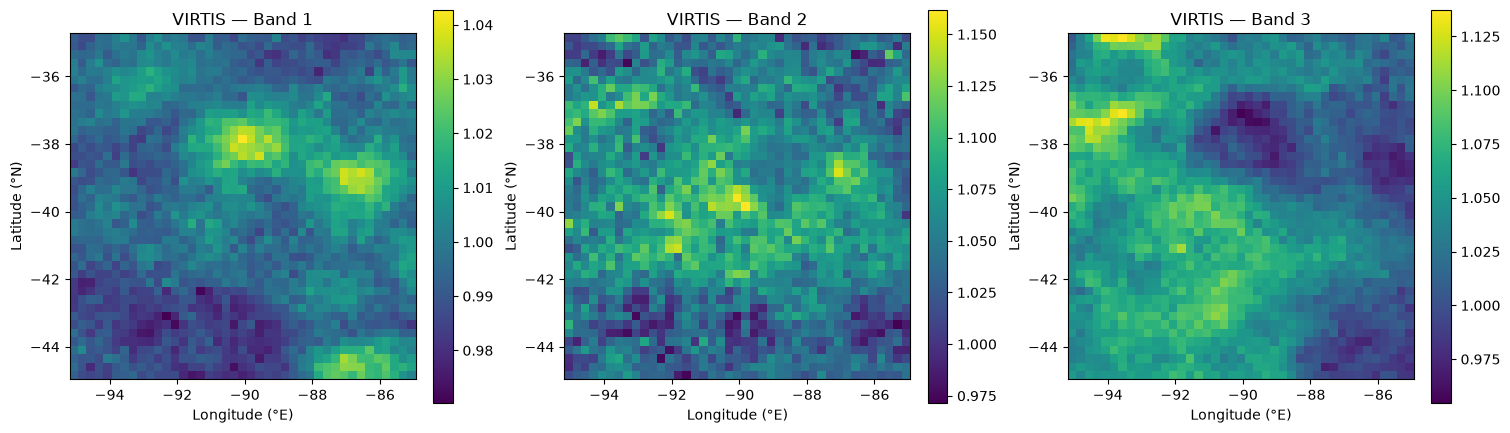

In [4]:
with rasterio.open(virtis_file) as src:

    bands = src.read(masked=True)

    R = 6051000.0

    extent = [
        np.rad2deg(src.bounds.left / R),
        np.rad2deg(src.bounds.right / R),
        np.rad2deg(src.bounds.bottom / R),
        np.rad2deg(src.bounds.top / R)
    ]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True
)

for i, ax in enumerate(axes):

    image = np.ma.masked_invalid(bands[i])

    im = ax.imshow(
        image,
        origin="upper",
        extent=extent,
        cmap="viridis",
        interpolation="nearest"
    )

    ax.set_title(f"VIRTIS — Band {i+1}")
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.show()

Pearson correlations:


,Band_1,Band_2,Band_3
Band_1,1.000,0.363,-0.494
Band_2,0.363,1.000,0.229
Band_3,-0.494,0.229,1.000



Spearman correlations:


,Band_1,Band_2,Band_3
Band_1,1.000,0.362,-0.455
Band_2,0.362,1.000,0.218
Band_3,-0.455,0.218,1.000


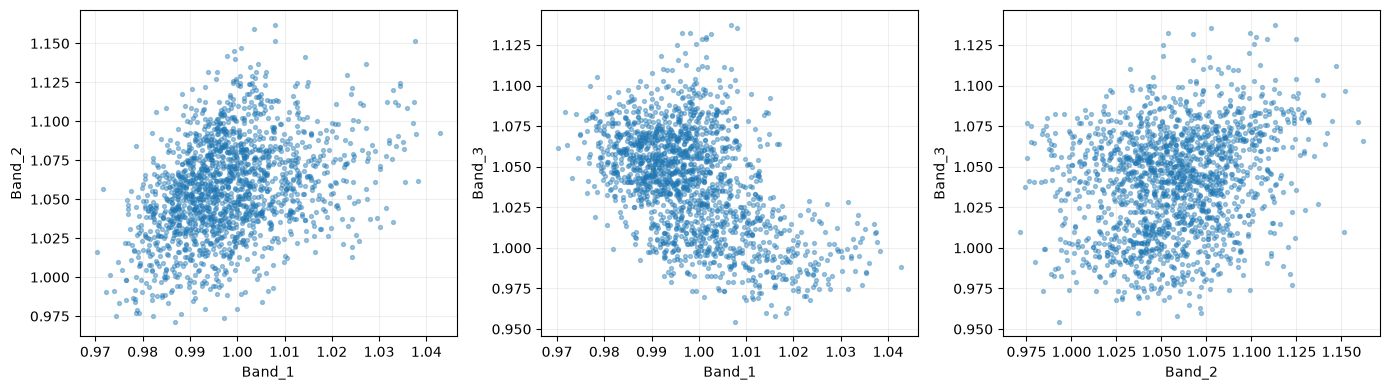

In [5]:
# Cell 4 — Correlation between VIRTIS raster bands

with rasterio.open(virtis_file) as src:
    data = src.read().astype(float)

band_df = pd.DataFrame({
    "Band_1": data[0].ravel(),
    "Band_2": data[1].ravel(),
    "Band_3": data[2].ravel()
})

band_df = band_df.replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("Pearson correlations:")
display(band_df.corr(method="pearson").round(3))

print("\nSpearman correlations:")
display(band_df.corr(method="spearman").round(3))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

pairs = [
    ("Band_1", "Band_2"),
    ("Band_1", "Band_3"),
    ("Band_2", "Band_3")
]

for ax, (x, y) in zip(axes, pairs):

    ax.scatter(
        band_df[x],
        band_df[y],
        s=8,
        alpha=0.4
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

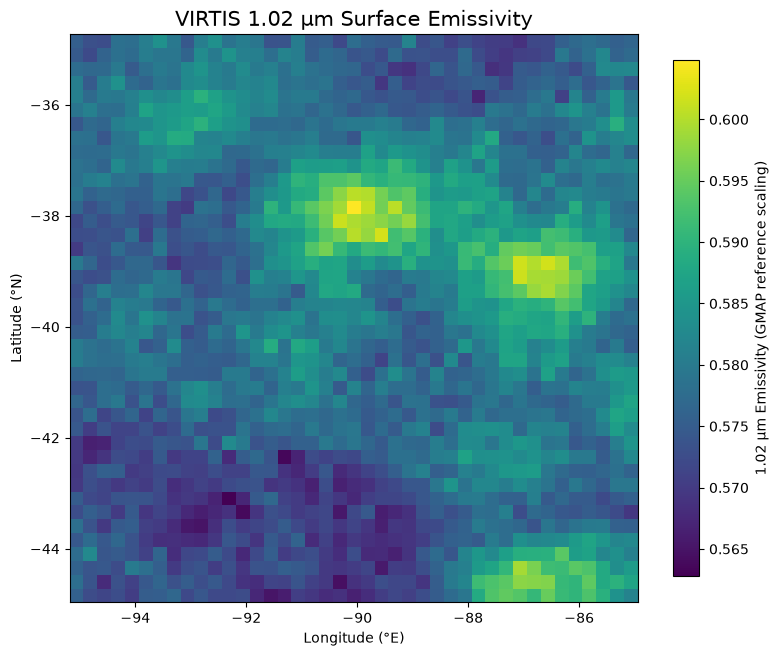

In [6]:
# Cell 5 — VIRTIS 1.02 µm emissivity

with rasterio.open(virtis_file) as src:

    emissivity_relative = src.read(1, masked=True)

    # GMAP assumed reference plains emissivity
    emissivity_102 = emissivity_relative * 0.58

    R = 6051000.0

    extent = [
        np.rad2deg(src.bounds.left / R),
        np.rad2deg(src.bounds.right / R),
        np.rad2deg(src.bounds.bottom / R),
        np.rad2deg(src.bounds.top / R)
    ]

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    emissivity_102,
    origin="upper",
    extent=extent,
    cmap="viridis",
    interpolation="nearest"
)

ax.set_title(
    "VIRTIS 1.02 µm Surface Emissivity",
    fontsize=15
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    im,
    ax=ax,
    label="1.02 µm Emissivity (GMAP reference scaling)",
    shrink=0.8
)

plt.tight_layout()
plt.show()